<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and recorded-source guide](README.md)

# 01 · The best ask does not price every share

How much of a hypothetical buy can a displayed book cover, and how does its average price differ from the best ask? We will retrieve one market's outcome identifiers, materialize both complete books, and walk their ask levels in SQL. The experiment increases requested shares while holding the captured evidence fixed.

**Recorded public data:** one Counter-Strike match market, “Spirit vs MOUZ (BO3) — BLAST Rivals Playoffs,” and its two outcome books, captured **2026-11-14T09:27:18.269332+00:00 to 2026-11-14T09:27:19.781912+00:00 (UTC)**. The response bodies are real and unmodified, with hashes and request timestamps in `fixtures/manifest.json`. The market was selected from a bounded high-volume discovery response; it is an illustration, not a representative sample. Gamma metadata and CLOB books are separate responses, not one atomic snapshot.

The model consumes displayed asks from cheapest to most expensive. It excludes fees, queue dynamics, latency, cancellations, hidden liquidity and subsequent replenishment. It sends no orders and makes no forecast or recommendation. Price is shown in **USDC per share**, not interpreted as a calibrated event probability.

## Choose size; keep the source fixed for the experiment

`SIZE_SHARES` is an integer from **1 to 500,000 shares**. Default **1,000** is a hypothetical analysis size, not an instruction to trade. The experiment uses **200,000**.

`DATA_MODE="replay"` serves the three exact captured responses to the unchanged worker through its supported base-URL overrides. `"live"` forwards only those same bounded public reads for the fixed condition and outcome IDs; current books may be empty or unavailable after the match. Unsupported requests and source failures stop execution with no replay fallback. Restart Kernel → Run All after editing.

In [1]:
SIZE_SHARES = 1000  # Shares per outcome; experiment: 200000
DATA_MODE = "replay"  # "replay" or "live"; hold replay fixed for the size experiment

In [2]:
import hashlib
import json
import os
from datetime import UTC, datetime
from decimal import Decimal
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import Markdown, display

from recorded_api import RecordedAPI

assert type(SIZE_SHARES) is int and 1 <= SIZE_SHARES <= 500000
assert DATA_MODE in {"replay", "live"}
run_utc = datetime.now(UTC).isoformat()
manifest = json.loads(Path("fixtures/manifest.json").read_text())
source = RecordedAPI(Path("fixtures"), DATA_MODE, Path("artifacts"))
env_names = ["POLYMARKET_GAMMA_URL", "POLYMARKET_CLOB_URL", "POLYMARKET_DATA_URL"]
previous_env = {name: os.environ.get(name) for name in env_names}
for name, path in zip(env_names, ["gamma", "clob", "unavailable"], strict=True):
    os.environ[name] = source.url + "/" + path
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)
colors = {"Spirit": "#287d85", "MOUZ": "#bd7735"}


def prose(text):
    display(Markdown(text))


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"{DATA_MODE.upper()} · public Polymarket CLOB · pre-fee displayed-book model · no orders sent\nSource books: {source_start} to {source_end} UTC",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.9))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-polymarket/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-polymarket/notebooks/pyproject.toml.

## Resolve the question to its outcome tokens

The literal `uvx` launch installs the worker from an immutable remote Git revision, with tested protocol dependencies. No local worker checkout is required. **`condition_id` identifies the question; `token_id` identifies one outcome.** Order books accept the latter. Unnest the worker's aligned outcome structs instead of independently joining the API's parallel JSON arrays.

We make one condition-ID lookup and two book reads, one per resulting token in this execution. This bounds the requested population. SQL `LIMIT` would restrict returned rows, not the completeness of a book response. The [official book API](https://docs.polymarket.com/api-reference/market-data/get-order-book) describes the token-level bid/ask response.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'polymarket' (
 TYPE vgi,
 LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-polymarket.git@c89399e51206d7406c03530e8f1ff367650fc923 --with vgi-python[http,haybarn]==0.51.0 --with vgi-rpc==0.53.1 --with httpx==0.28.1 --with httpx2==2.16.0 --with pyarrow==25.0.0 --with numpy==2.5.4 vgi-polymarket'
);
CREATE TABLE selected_market AS
SELECT * FROM polymarket.market('0x6cd1330980f778692947d0ef31f533b0375046b335c8845ca265c8c42d8db753');
CREATE TABLE outcomes AS
SELECT condition_id,question,o.item.outcome_index AS outcome_index,
 o.item.outcome AS outcome,o.item.token_id AS token_id
FROM selected_market CROSS JOIN UNNEST(outcomes) AS o(item);
CREATE TABLE book_rows AS
SELECT o.outcome,b.* FROM outcomes o,LATERAL polymarket.orderbook(o.token_id) b;

,Count


In [4]:
%%sql market_table <<
SELECT outcome_index,outcome,condition_id,token_id,question FROM outcomes ORDER BY outcome_index;

In [5]:
display(market_table)
assert con.execute("SELECT count(*) FROM selected_market").fetchone()[0] == 1
assert set(market_table.token_id) == set(manifest["tokens"])
assert con.execute("SELECT count(*)=count(DISTINCT token_id) FROM outcomes").fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM book_rows WHERE price IS NULL OR size IS NULL OR price<0 OR price>1 OR size<=0 OR side NOT IN ('bid','ask')"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM book_rows WHERE condition_id IS DISTINCT FROM ?", [manifest["condition_id"]]
    ).fetchone()[0]
    == 0
)
raw_books = [
    book
    for entry in manifest["entries"]
    if entry["method"] == "POST"
    for book in json.loads((Path("artifacts") / entry["filename"]).read_text())
]
expected = sorted(
    (b["asset_id"], side, Decimal(x["price"]), Decimal(x["size"]))
    for b in raw_books
    for field, side in [("bids", "bid"), ("asks", "ask")]
    for x in b.get(field, [])
)
actual = sorted(con.execute("SELECT token_id,side,price,size FROM book_rows").fetchall())
assert actual == expected, "Worker levels differ from the actual complete response"
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute(
            "SELECT token_id,side,price,size,book_timestamp AT TIME ZONE 'UTC' FROM book_rows ORDER BY token_id,side,price,size"
        ).fetchall(),
        default=str,
        separators=(",", ":"),
    ).encode()
).hexdigest()
prose(
    f"The bounded lookup resolved **{len(market_table)} outcomes** and returned **{len(actual)} bid/ask levels**. Every returned level agrees with the complete response body's price and size, checked with Decimal arithmetic. Book fingerprint: `{fingerprint}`. Run clock: **{run_utc}**; this is separate from source book timestamps below."
)

,outcome_index,outcome,condition_id,token_id,question
0,0,Spirit,0x6cd1330980f778692947d0ef31f533b0375046b335c8...,1116808278738754461307158772794349732927605341...,Counter-Strike: Spirit vs MOUZ (BO3) - BLAST R...
1,1,MOUZ,0x6cd1330980f778692947d0ef31f533b0375046b335c8...,3524361020311414047563871655585266894646797416...,Counter-Strike: Spirit vs MOUZ (BO3) - BLAST R...


The bounded lookup resolved **2 outcomes** and returned **198 bid/ask levels**. Every returned level agrees with the complete response body's price and size, checked with Decimal arithmetic. Book fingerprint: `1da7c14f2eb98aec1cc6eb577cfbd96fd38f7c926918c3ee548a55dbf687aba7`. Run clock: **2026-11-14T09:30:49.007179+00:00**; this is separate from source book timestamps below.

## Check availability before pricing a fill

Best bid is the maximum bid; best ask is the minimum ask. Aggregate repeated price levels before computing cumulative shares. Keep all outcomes with LEFT JOINs, including those with no returned levels. The worker emits no rows for both a missing book and an empty book, so that condition is labelled **no returned levels** rather than a zero-valued quote.

If any returned level has an unavailable or invalid price/size, the notebook stops instead of discarding it. A nonempty book with no asks cannot supply this buy model. Book timestamps describe the source response, not our run clock.

In [6]:
%%sql
CREATE TABLE levels AS
SELECT token_id,outcome,side,price,sum(size) AS size FROM book_rows
GROUP BY token_id,outcome,side,price;
CREATE TABLE availability AS
SELECT o.outcome_index,o.outcome,o.token_id,count(b.token_id) AS returned_levels,
 count(*) FILTER(WHERE b.side='ask') AS ask_levels,
 max(b.price) FILTER(WHERE b.side='bid') AS best_bid,
 min(b.price) FILTER(WHERE b.side='ask') AS best_ask,
 sum(b.size) FILTER(WHERE b.side='ask') AS displayed_ask_shares,
 min(b.book_timestamp) AT TIME ZONE 'UTC' AS first_book_time_utc,max(b.book_timestamp) AT TIME ZONE 'UTC' AS last_book_time_utc
FROM outcomes o LEFT JOIN book_rows b USING(token_id,outcome)
GROUP BY o.outcome_index,o.outcome,o.token_id;

,Count


In [7]:
%%sql availability <<
SELECT outcome,returned_levels,ask_levels,best_bid,best_ask,best_ask-best_bid AS spread,
 displayed_ask_shares,first_book_time_utc,last_book_time_utc,
 CASE WHEN returned_levels=0 THEN 'No returned levels'
 WHEN ask_levels=0 THEN 'No returned asks' ELSE 'Ask depth available' END AS availability
FROM availability ORDER BY outcome_index;

In [8]:
display(availability)
assert len(availability) == len(market_table)
assert con.execute("SELECT count(*) FROM availability WHERE best_bid>best_ask").fetchone()[0] == 0
assert (
    con.execute(
        "SELECT count(*) FROM availability WHERE first_book_time_utc IS DISTINCT FROM last_book_time_utc"
    ).fetchone()[0]
    == 0
)
source_start = availability.first_book_time_utc.min()
source_end = availability.last_book_time_utc.max()
prose(
    f"Source book time range: **{source_start} to {source_end} UTC**. **{int((availability.ask_levels > 0).sum())}/{len(availability)} outcomes** have returned ask depth. A narrow spread describes only the touch; the size available at that price and behind it determines the fill below. No asks means an unavailable buy price, not a price of zero."
)

,outcome,returned_levels,ask_levels,best_bid,best_ask,spread,displayed_ask_shares,first_book_time_utc,last_book_time_utc,availability
0,Spirit,99,8,0.91,0.92,0.01,138840.70,2026-11-14 09:27:18.228,2026-11-14 09:27:18.228,Ask depth available
1,MOUZ,99,91,0.08,0.09,0.01,482301.87,2026-11-14 09:27:18.228,2026-11-14 09:27:18.228,Ask depth available


Source book time range: **2026-11-14 09:27:18.228000 to 2026-11-14 09:27:18.228000 UTC**. **2/2 outcomes** have returned ask depth. A narrow spread describes only the touch; the size available at that price and behind it determines the fill below. No asks means an unavailable buy price, not a price of zero.

## Walk asks from the lowest price upward

For each level, take the smaller of its available shares and the request remaining after all cheaper levels. Sum **taken shares × level price** for pre-fee notional. Divide by filled shares for the weighted average; use NULL if nothing fills. All outcomes remain in the result, and unfilled shares are explicit.

The books are already materialized. Changing `SIZE_SHARES` changes this SQL calculation, not the request population or recorded source. Average prices are derived ratios; source price/size and notional use decimal columns, while SQL division produces a floating-point ratio for display.

In [9]:
%%sql
CREATE TABLE ask_depth AS
SELECT *,coalesce(sum(size) OVER(PARTITION BY token_id ORDER BY price
 ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING),0) AS shares_before,
 sum(size) OVER(PARTITION BY token_id ORDER BY price ROWS UNBOUNDED PRECEDING) AS cumulative_shares
FROM levels WHERE side='ask';
CREATE TABLE consumption AS
SELECT *,least(size,greatest(0,{{SIZE_SHARES}}::DECIMAL(28,6)-shares_before)) AS taken_shares
FROM ask_depth;
CREATE TABLE fills AS
SELECT o.outcome_index,o.outcome,o.token_id,{{SIZE_SHARES}} AS requested_shares,
 coalesce(sum(c.taken_shares),0) AS filled_shares,
 {{SIZE_SHARES}}-coalesce(sum(c.taken_shares),0) AS unfilled_shares,
 sum(c.taken_shares*c.price) AS pre_fee_notional_usdc,
 sum(c.taken_shares*c.price)/nullif(sum(c.taken_shares),0) AS average_price,
 min(c.price) AS touch_ask,
 max(c.price) FILTER(WHERE c.taken_shares>0) AS worst_consumed_price,
 count(*) FILTER(WHERE c.taken_shares>0) AS levels_consumed
FROM outcomes o LEFT JOIN consumption c USING(token_id,outcome)
GROUP BY o.outcome_index,o.outcome,o.token_id;

,Count


In [10]:
%%sql fills <<
SELECT outcome,requested_shares,filled_shares,unfilled_shares,
 round(pre_fee_notional_usdc,4) AS pre_fee_notional_usdc,
 touch_ask,round(average_price,6) AS average_price,
 worst_consumed_price,levels_consumed,filled_shares=requested_shares AS fully_covered
FROM fills ORDER BY outcome_index;

,outcome,requested_shares,filled_shares,unfilled_shares,pre_fee_notional_usdc,touch_ask,average_price,worst_consumed_price,levels_consumed,fully_covered
0,Spirit,1000,1000.0,0.0,920.0,0.92,0.92,0.92,1,True
1,MOUZ,1000,1000.0,0.0,90.0,0.09,0.09,0.09,1,True


At **1,000 shares per outcome**, **2/2** books cover the entire hypothetical request. Across these separate scenarios, **0.00 shares** remain unfilled. These are independent hypothetical buys, not a combined portfolio. Filling only part of a request prices only that part; it does not estimate the cost or availability of the remainder.

**Spirit:** filled **1,000.00/1,000 shares**, average **0.920000 USDC/share** versus touch **0.920000**, consuming **1 levels**. Unfilled: **0.00 shares**.

**MOUZ:** filled **1,000.00/1,000 shares**, average **0.090000 USDC/share** versus touch **0.090000**, consuming **1 levels**. Unfilled: **0.00 shares**.

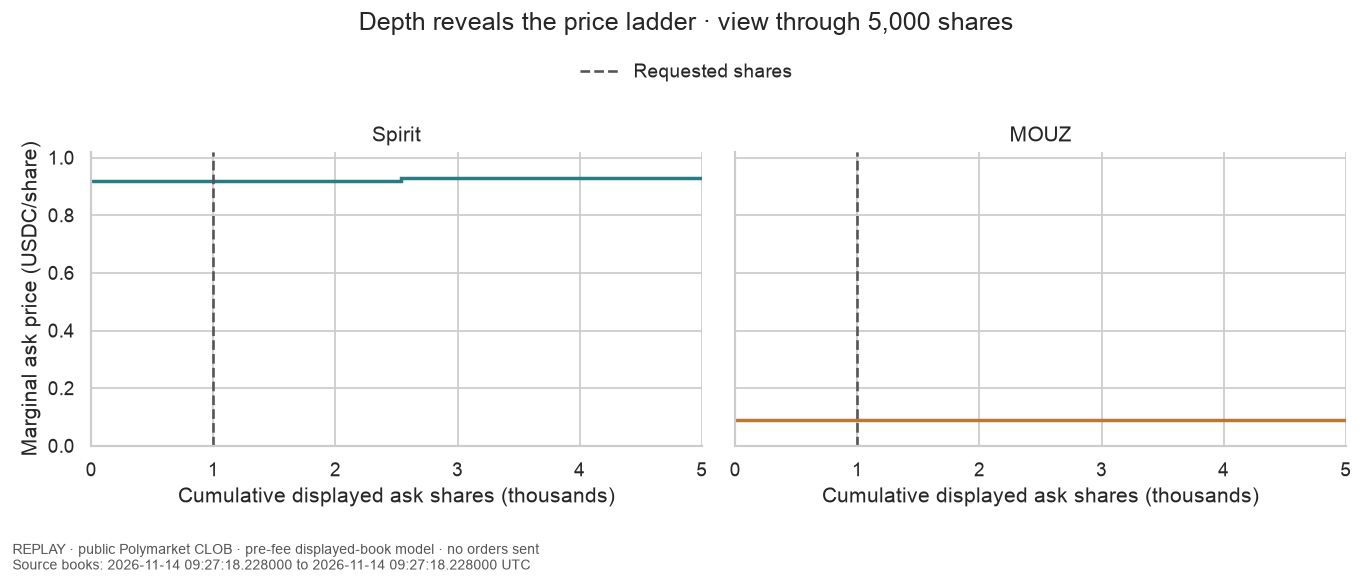

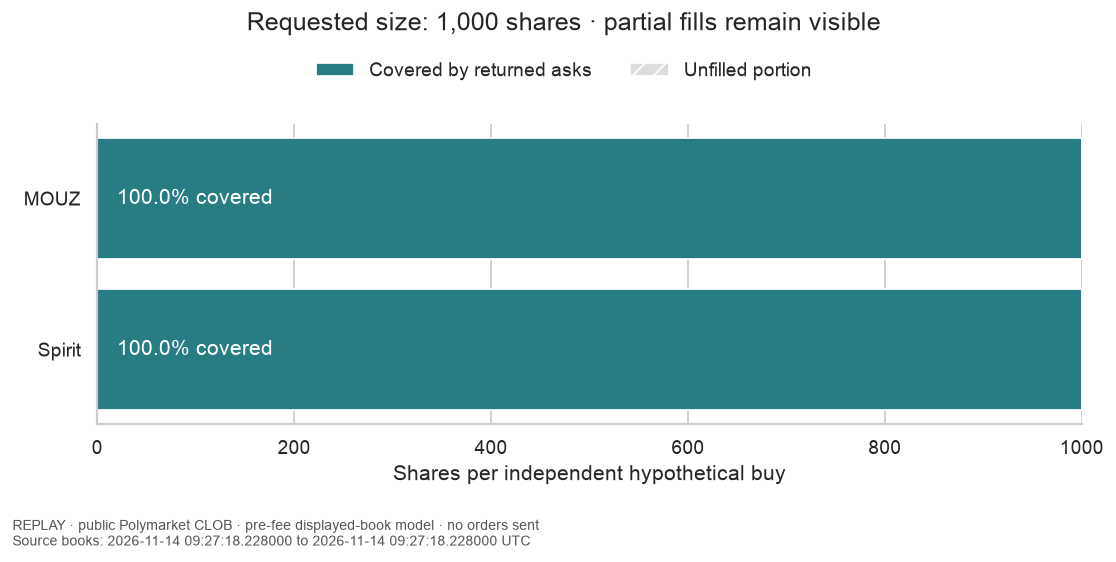

Request audit: **3 HTTP reads**, **16,755 response bytes**, no additional requests for the charts or fill calculation. POST `/books` is the API's batch read; no order-entry endpoint is used. The first chart clips its display at **5,000 shares**; the calculation uses every returned level. Any depth beyond that view is retained in the model.

2339

In [11]:
display(fills)
full = con.execute("SELECT * FROM fills ORDER BY outcome_index").df()
assert len(full) == len(market_table)
assert ((full.filled_shares >= 0) & (full.filled_shares <= SIZE_SHARES)).all()
assert np.allclose(full.filled_shares + full.unfilled_shares, SIZE_SHARES)
assert (
    con.execute("SELECT count(*) FROM consumption WHERE taken_shares<0 OR taken_shares>size").fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM fills WHERE filled_shares>0 AND (average_price<touch_ask-1e-12 OR average_price>worst_consumed_price+1e-12)"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM fills WHERE (filled_shares=0) IS DISTINCT FROM (average_price IS NULL)"
    ).fetchone()[0]
    == 0
)
for row in con.execute(
    "SELECT token_id,filled_shares,pre_fee_notional_usdc,average_price FROM fills"
).fetchall():
    token, filled, notional, average = row
    book = next((b for b in raw_books if b["asset_id"] == token), {})
    left = Decimal(SIZE_SHARES)
    reference_cost = Decimal(0)
    for level in sorted(book.get("asks", []), key=lambda x: Decimal(x["price"])):
        take = min(left, Decimal(level["size"]))
        left -= take
        reference_cost += take * Decimal(level["price"])
    assert filled == Decimal(SIZE_SHARES) - left
    if filled:
        assert notional == reference_cost
        assert abs(average - float(reference_cost / filled)) < 1e-10
covered = int((full.unfilled_shares == 0).sum())
prose(
    f"At **{SIZE_SHARES:,} shares per outcome**, **{covered}/{len(full)}** books cover the entire hypothetical request. Across these separate scenarios, **{full.unfilled_shares.sum():,.2f} shares** remain unfilled. These are independent hypothetical buys, not a combined portfolio. Filling only part of a request prices only that part; it does not estimate the cost or availability of the remainder."
)
for r in full.itertuples():
    if r.filled_shares > 0:
        prose(
            f"**{r.outcome}:** filled **{r.filled_shares:,.2f}/{SIZE_SHARES:,} shares**, average **{r.average_price:.6f} USDC/share** versus touch **{r.touch_ask:.6f}**, consuming **{r.levels_consumed} levels**. Unfilled: **{r.unfilled_shares:,.2f} shares**."
        )
    else:
        prose(f"**{r.outcome}:** no returned asks to price this request; average price unavailable.")
depth = con.execute("SELECT * FROM ask_depth ORDER BY token_id,price").df()
fig, axes = plt.subplots(1, len(full), figsize=(11, 4.6), sharey=True, squeeze=False)
view_max = max(5000, SIZE_SHARES * 1.1)
for ax, r in zip(axes.flat, full.itertuples(), strict=True):
    d = depth[depth.token_id == r.token_id]
    if len(d):
        ax.stairs(
            d.price.astype(float),
            np.r_[0, d.cumulative_shares.astype(float)] / 1000,
            baseline=None,
            color=colors.get(r.outcome, "#287d85"),
            linewidth=2,
        )
    else:
        ax.text(0.5, 0.5, "No returned ask levels", transform=ax.transAxes, ha="center")
    ax.axvline(SIZE_SHARES / 1000, color="#555555", ls="--", label="Requested shares")
    ax.set(
        title=r.outcome,
        xlabel="Cumulative displayed ask shares (thousands)",
        xlim=(0, view_max / 1000),
        ylim=(0, 1.02),
    )

axes[0, 0].set_ylabel("Marginal ask price (USDC/share)")
fig.legend(
    *axes[0, 0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.92), frameon=False
)
fig.suptitle(f"Depth reveals the price ladder · view through {view_max:,.0f} shares")
finish(fig)
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(full))
ax.barh(y, full.filled_shares, color="#287d85", label="Covered by returned asks")
ax.barh(
    y, full.unfilled_shares, left=full.filled_shares, color="#dddddd", hatch="//", label="Unfilled portion"
)
for i, r in enumerate(full.itertuples()):
    ax.text(
        SIZE_SHARES * 0.02,
        i,
        f"{100 * r.filled_shares / SIZE_SHARES:.1f}% covered",
        ha="left",
        va="center",
        color="white" if r.filled_shares > SIZE_SHARES * 0.25 else "#222222",
    )
ax.set(
    yticks=y,
    yticklabels=full.outcome,
    xlabel="Shares per independent hypothetical buy",
    xlim=(0, SIZE_SHARES),
)
fig.suptitle(f"Requested size: {SIZE_SHARES:,} shares · partial fills remain visible")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2, frameon=False)
finish(fig)
assert len(source.requests) == 3 and all(r["status"] == 200 for r in source.requests), source.requests
prose(
    f"Request audit: **{len(source.requests)} HTTP reads**, **{sum(r['bytes'] for r in source.requests):,} response bytes**, no additional requests for the charts or fill calculation. POST `/books` is the API's batch read; no order-entry endpoint is used. The first chart clips its display at **{view_max:,.0f} shares**; the calculation uses every returned level. Any depth beyond that view is retained in the model."
)
Path("artifacts/analysis-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "run_utc": run_utc,
            "size_shares": SIZE_SHARES,
            "book_fingerprint": fingerprint,
            "requests": source.requests,
            "fills": full.to_dict(orient="records"),
        },
        default=str,
        indent=2,
    )
)

## Experiment: increase requested size on the same recorded books

Keep `DATA_MODE="replay"` and change only `SIZE_SHARES` from **1,000 to 200,000**. Predict that filled shares cannot decrease, coverage percentage cannot increase, and the weighted average cannot improve while consuming asks in ascending price order. Inspect the partial-fill table and coverage chart rather than treating a reported average as a price for the entire request.

The raw fingerprint, outcome IDs, source timestamps, source level counts and three-request audit must remain identical. The plot's horizontal view expands with the requested size; its price axis remains fixed. Restore **1,000** afterwards. This comparison isolates size against one displayed snapshot. It does not model future book changes, fees, market impact beyond those displayed levels, or the likelihood of either outcome.

In [12]:
con.close()
source.close()
for name, value in previous_env.items():
    if value is None:
        os.environ.pop(name, None)
    else:
        os.environ[name] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)